# 2. Molecular dynamics, from 64 to 1,000 atoms

We run molecular dynamics (MD) of crystalline silicon at 300 K with 7net-0: first on a small cell with
each backend, to see the same dynamics at different speeds; then on larger cells with the fused
kernels; and finally a longer run, from which we compute the radial distribution function.

MD needs the forces at every time step, so the speed of one force call is the speed of the simulation.
We report it as steps per second and as simulated nanoseconds per day at a 1 fs time step.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np

import _tutorial as T

warnings.filterwarnings('ignore', message='.*torch.jit.script.*')   # deprecation inside a dependency, harmless here
plt.rcParams['figure.dpi'] = 200   # sharp inline figures
T.machine_report()

machine : Apple M5 Pro, 52 GB memory, Darwin 27.2.0
python  : 3.13.9, torch 2.15.0, sevenn 0.12.2.dev0
Apple GPU (MPS): yes; fused kernels: available


In [2]:
from ase import units
from ase.build import bulk
from ase.constraints import FixCom
from ase.md.langevin import Langevin


def silicon(n):
    return bulk('Si', 'diamond', a=5.43, cubic=True).repeat((n, n, n))


def run_md(atoms, calc, device, steps, T_K=300.0, dt_fs=1.0, seed=1, log_every=0):
    """Langevin NVT; returns steps per second over the measured steps and the temperature log."""
    atoms = atoms.copy()
    atoms.set_constraint(FixCom())   # keep the centre of mass fixed, as ASE recommends for Langevin
    atoms.calc = calc
    T.thermalize(atoms, T_K, np.random.default_rng(seed))
    dyn = Langevin(atoms, dt_fs * units.fs, temperature_K=T_K, friction=0.01 / units.fs, fixcm=False,
                   rng=np.random.default_rng(seed + 1))
    dyn.run(5)                      # warm-up, not timed
    temps = []
    if log_every:
        dyn.attach(lambda: temps.append(atoms.get_temperature()), interval=log_every)
    T.sync(device)
    t = time.perf_counter()
    dyn.run(steps)
    T.sync(device)
    return steps / (time.perf_counter() - t), temps, atoms


def ns_per_day(sps, dt_fs=1.0):
    return sps * dt_fs * 86400 / 1e6

## Same system, three backends

64 atoms, 20 steps each. The CPU run takes the longest; it is here to show what the fused kernels
replace.

In [3]:
small = silicon(2)
speed = {}
for label, device, opt in T.available_backends():
    sps, _, _ = run_md(small, T.calculator('7net-0', device, opt), device, steps=20)
    speed[label] = sps
    print(f'{label:18s} {sps:6.1f} steps/s  = {ns_per_day(sps):5.2f} ns/day')

CPU, e3nn             6.8 steps/s  =  0.59 ns/day


Apple GPU, e3nn      12.8 steps/s  =  1.10 ns/day


Apple GPU, fused     70.9 steps/s  =  6.13 ns/day


## Larger cells with the fused kernels

The cost grows with the number of atoms (more precisely, with the number of neighbor pairs). Cells
that would not fit in memory on this machine are skipped.

   64 atoms:   63.8 steps/s =  5.51 ns/day (Apple GPU, fused)


  216 atoms:   47.8 steps/s =  4.13 ns/day (Apple GPU, fused)


  512 atoms:   28.1 steps/s =  2.43 ns/day (Apple GPU, fused)


 1000 atoms:   15.7 steps/s =  1.36 ns/day (Apple GPU, fused)
peak memory of this notebook so far: 1.5 GB (process), 1.3 GB (GPU driver now)


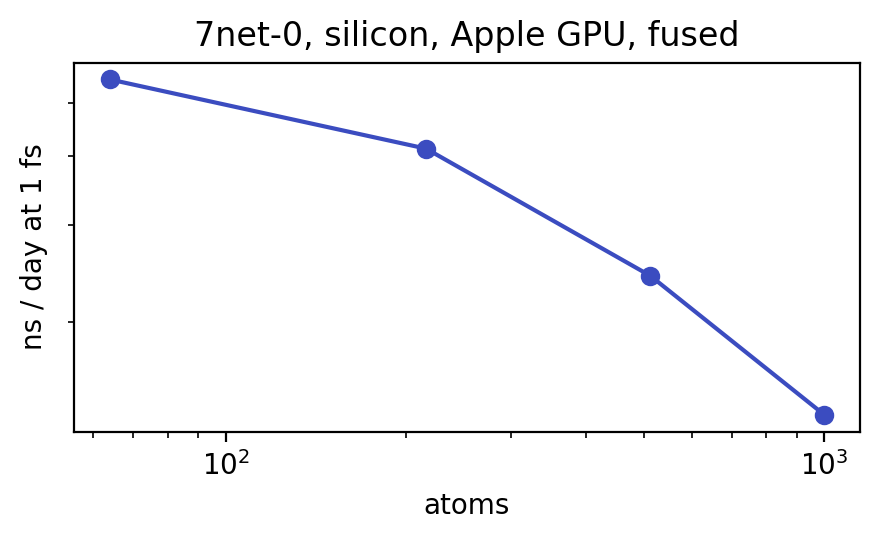

In [4]:
label, device, opt = T.best_backend()
calc = T.calculator('7net-0', device, opt)
sizes = T.cells_for_memory([2, 3, 4, 5], gb_per_1000_atoms=1.5, natoms=[64, 216, 512, 1000])
scan = []
for n in sizes:
    sps, _, _ = run_md(silicon(n), calc, device, steps=30)
    scan.append((8 * n ** 3, sps))
    print(f'{8 * n ** 3:5d} atoms: {sps:6.1f} steps/s = {ns_per_day(sps):5.2f} ns/day ({label})')
rss, drv = T.memory_gb()
print(f'peak memory of this notebook so far: {rss:.1f} GB (process), {drv:.1f} GB (GPU driver now)')

fig, ax = plt.subplots(figsize=(4.5, 2.8))
ax.plot([s[0] for s in scan], [ns_per_day(s[1]) for s in scan], 'o-', color='#3B4CC0')
ax.set_xlabel('atoms')
ax.set_ylabel('ns / day at 1 fs')
ax.set_xscale('log')
ax.set_yscale('log')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:g}'))
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set_title(f'7net-0, silicon, {label}')
plt.tight_layout()
plt.show()

## A longer run and the radial distribution function

512 atoms at 300 K: 1 ps to equilibrate, then 2 ps of production, saving a frame every 20 fs. On an
M5 Pro this takes about two minutes; on a MacBook Air a few more. Set `LONG = True` for a 20 ps run.

The trajectory can be opened in OVITO or with `ase gui md_si512.traj`.

2000 steps in 69 s: 29.0 steps/s = 2.51 ns/day


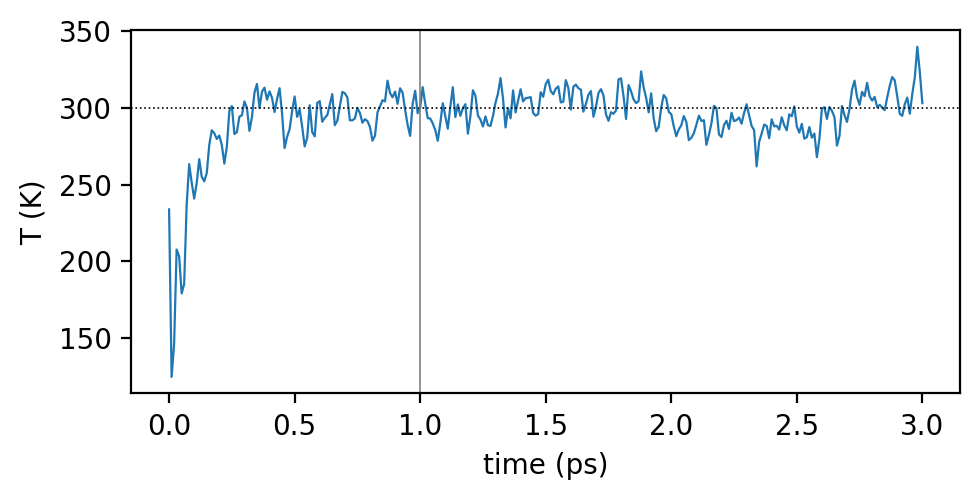

In [5]:
from ase.io.trajectory import Trajectory

LONG = False
n_eq, n_prod = 1000, (20000 if LONG else 2000)
atoms = silicon(4)
sps, temps, atoms = run_md(atoms, calc, device, steps=n_eq, log_every=10)
dyn = Langevin(atoms, 1.0 * units.fs, temperature_K=300.0, friction=0.01 / units.fs, fixcm=False, rng=np.random.default_rng(3))
traj = Trajectory('md_si512.traj', 'w', atoms)
dyn.attach(traj.write, interval=20)
dyn.attach(lambda: temps.append(atoms.get_temperature()), interval=10)
t = time.perf_counter()
dyn.run(n_prod)
dt = time.perf_counter() - t
traj.close()
print(f'{n_prod} steps in {dt:.0f} s: {n_prod / dt:.1f} steps/s = {ns_per_day(n_prod / dt):.2f} ns/day')

fig, ax = plt.subplots(figsize=(5, 2.6))
ax.plot(np.arange(len(temps)) * 10 / 1000, temps, lw=0.8)
ax.axhline(300, color='k', lw=0.6, ls=':')
ax.axvline(n_eq / 1000, color='grey', lw=0.6)
ax.set_xlabel('time (ps)')
ax.set_ylabel('T (K)')
plt.tight_layout()
plt.show()

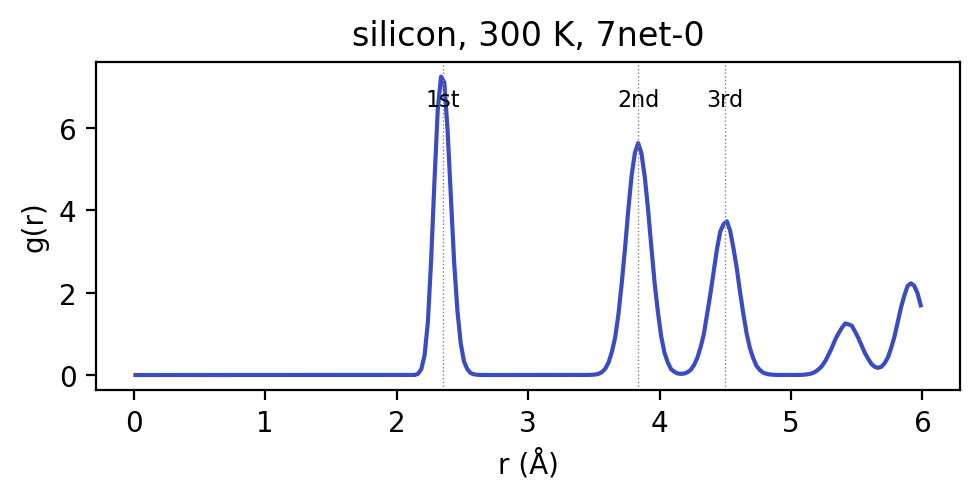

In [6]:
from ase.io import read


def rdf(frames, rmax=6.0, nbins=240):
    """g(r) averaged over frames, minimum-image distances (cubic cell, rmax below half the cell)."""
    edges = np.linspace(0, rmax, nbins + 1)
    hist = np.zeros(nbins)
    for a in frames:
        d = a.get_all_distances(mic=True)[np.triu_indices(len(a), 1)]
        hist += np.histogram(d, edges)[0]
    n, V = len(frames[0]), frames[0].get_volume()
    shell = 4 / 3 * np.pi * (edges[1:] ** 3 - edges[:-1] ** 3)
    g = hist * 2 / (len(frames) * n * (n / V) * shell)
    return 0.5 * (edges[1:] + edges[:-1]), g


frames = read('md_si512.traj', index=':')
r, g = rdf(frames)
fig, ax = plt.subplots(figsize=(5, 2.6))
ax.plot(r, g, color='#3B4CC0')
for d, lab in ((2.35, '1st'), (3.84, '2nd'), (4.50, '3rd')):
    ax.axvline(d, color='grey', lw=0.5, ls=':')
    ax.text(d, g.max() * 0.9, lab, ha='center', fontsize=8)
ax.set_xlabel('r (Å)')
ax.set_ylabel('g(r)')
ax.set_title('silicon, 300 K, 7net-0')
plt.tight_layout()
plt.show()

The peaks sit at the first, second and third neighbor distances of diamond silicon (2.35, 3.84 and
4.50 Å), broadened by thermal motion.

**Next experiments:** heat the crystal to 1700 K to watch it melt (and the g(r) change); use the larger
`'7net-l3i5'`; or, on a machine with more memory, a 6 × 6 × 6 cell (1,728 atoms).